Round: 0 Alive Nodes: 100 Dead Nodes: 0 Remaining Energy: 49.9465
Round: 50 Alive Nodes: 100 Dead Nodes: 0 Remaining Energy: 47.4837
Round: 100 Alive Nodes: 100 Dead Nodes: 0 Remaining Energy: 45.1091
Round: 150 Alive Nodes: 100 Dead Nodes: 0 Remaining Energy: 42.7018
Round: 200 Alive Nodes: 100 Dead Nodes: 0 Remaining Energy: 40.3098
Round: 250 Alive Nodes: 100 Dead Nodes: 0 Remaining Energy: 37.8816
Round: 300 Alive Nodes: 100 Dead Nodes: 0 Remaining Energy: 35.4691
Round: 350 Alive Nodes: 100 Dead Nodes: 0 Remaining Energy: 33.0646
Round: 400 Alive Nodes: 100 Dead Nodes: 0 Remaining Energy: 30.659
Round: 450 Alive Nodes: 100 Dead Nodes: 0 Remaining Energy: 28.2461

--- Final Results ---
Total Rounds: 500
Alive Nodes: 100
Dead Nodes: 0
Remaining Energy: 25.8671
Total Packets Delivered: 50000


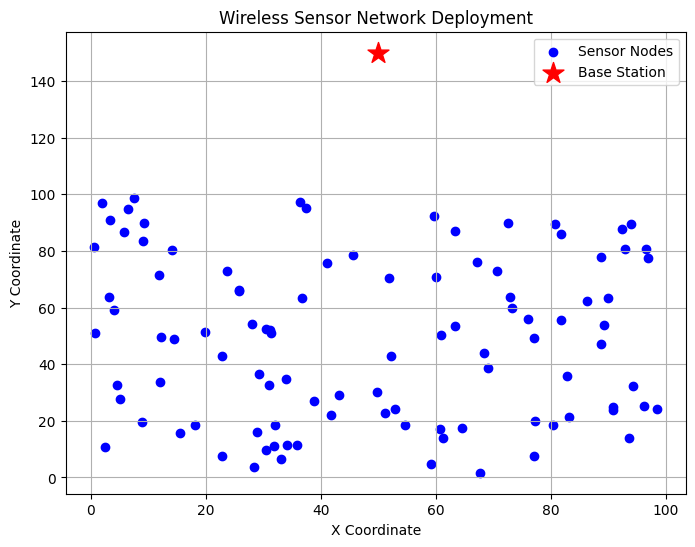

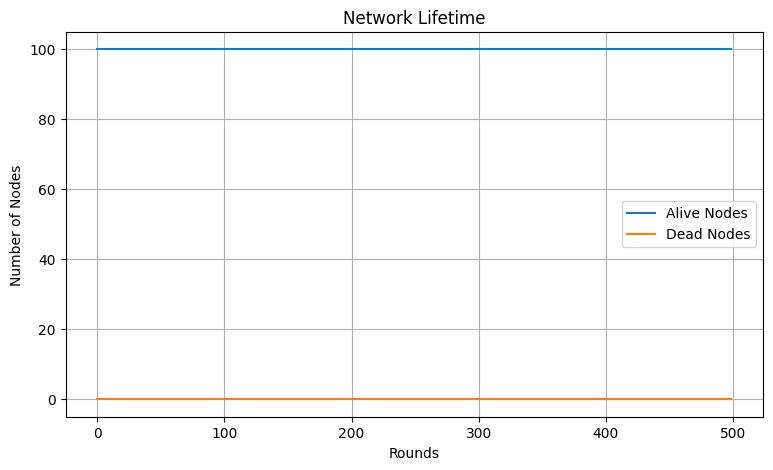

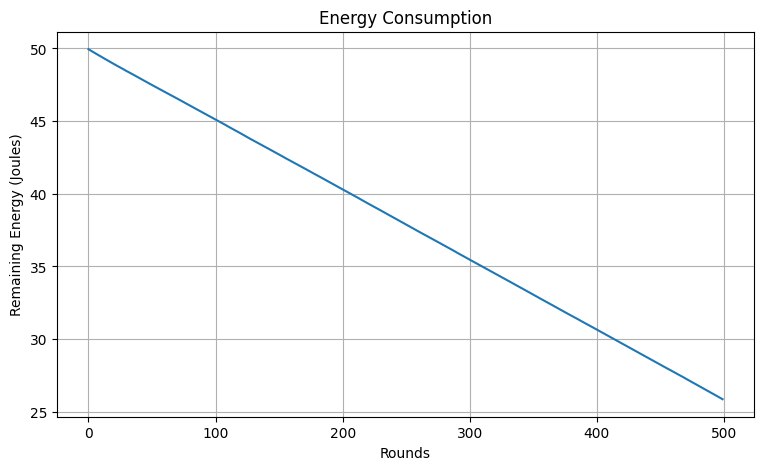

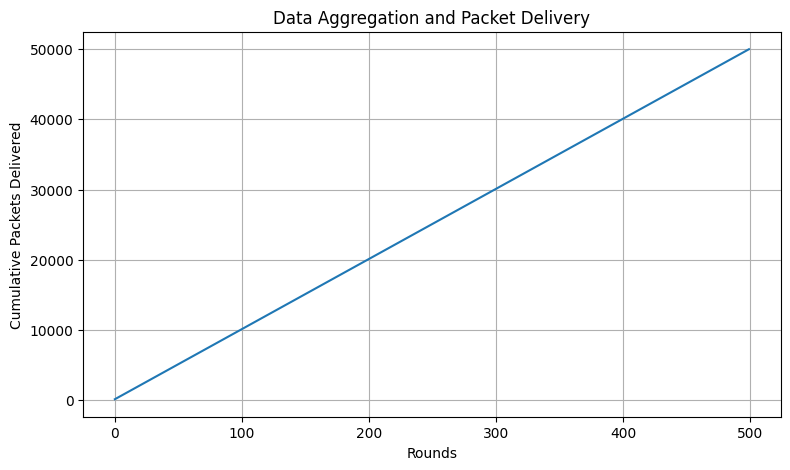

In [3]:

import numpy as np
import matplotlib.pyplot as plt

# Network parameters
N = 100
AREA = 100
INITIAL_ENERGY = 0.5
SINK = np.array([50, 150])
ROUNDS = 500
CLUSTERS = 5
PACKET_SIZE = 4000

# Energy model
E_ELEC = 50e-9
E_DA = 5e-9
E_FS = 10e-12
E_MP = 0.0013e-12

D0 = np.sqrt(E_FS / E_MP)

np.random.seed(42)

# Deploy sensor nodes
nodes = np.random.uniform(0, AREA, (N, 2))
energy = np.full(N, INITIAL_ENERGY)

alive_history = []
energy_history = []
dead_history = []
packets_history = []

def distance(a, b):
    return np.linalg.norm(a - b)

# Calculate transmission energy
def tx_energy(d):
    if d < D0:
        return (E_ELEC * PACKET_SIZE +
                E_FS * PACKET_SIZE * d**2)
    else:
        return (E_ELEC * PACKET_SIZE +
                E_MP * PACKET_SIZE * d**4)

# Calculate reception energy
def rx_energy():
    return E_ELEC * PACKET_SIZE

# Energy-aware cluster head selection
def select_cluster_heads(active):
    scores = []

    for i in active:
        other = [j for j in active if j != i]

        if len(other) > 0:
            avg_dist = np.mean([
                distance(nodes[i], nodes[j])
                for j in other
            ])
        else:
            avg_dist = 0

        energy_score = energy[i] / INITIAL_ENERGY

        distance_score = 1 / (1 + avg_dist)

        sink_score = 1 / (1 + distance(nodes[i], SINK) / AREA)

        score = (0.6 * energy_score +
                 0.2 * distance_score +
                 0.2 * sink_score)

        scores.append((score, i))

    scores.sort(reverse=True)

    return [i for score, i in scores[:CLUSTERS]]

# Main simulation
for r in range(ROUNDS):

    active = np.where(energy > 0)[0]

    if len(active) == 0:
        break

    # Select cluster heads
    heads = select_cluster_heads(active)

    # Assign nodes to nearest cluster head
    clusters = {h: [] for h in heads}

    for node in active:
        if node in heads:
            continue

        nearest = min(
            heads,
            key=lambda h: distance(nodes[node], nodes[h])
        )

        clusters[nearest].append(node)

    packets = 0

    # Communication and data aggregation
    for head, members in clusters.items():

        # Member nodes send data to CH
        for node in members:
            d = distance(nodes[node], nodes[head])
            cost = tx_energy(d)

            if energy[node] >= cost:
                energy[node] -= cost
                packets += 1

                receive_cost = rx_energy()
                energy[head] -= receive_cost

                if energy[head] <= 0:
                    energy[head] = 0

        # Data aggregation at cluster head
        aggregation_cost = (
            E_DA * PACKET_SIZE *
            (len(members) + 1)
        )

        if energy[head] > aggregation_cost:
            energy[head] -= aggregation_cost

            # Transmit aggregated data to sink
            d_sink = distance(nodes[head], SINK)
            cost = tx_energy(d_sink)

            if energy[head] >= cost:
                energy[head] -= cost
                packets += 1

        energy[head] = max(0, energy[head])

    # Record network performance
    alive = np.sum(energy > 0)

    alive_history.append(alive)
    dead_history.append(N - alive)
    energy_history.append(np.sum(energy))
    packets_history.append(packets)

    if r % 50 == 0:
        print("Round:", r,
              "Alive Nodes:", alive,
              "Dead Nodes:", N - alive,
              "Remaining Energy:", round(np.sum(energy), 4))

# Final results
print("\n--- Final Results ---")
print("Total Rounds:", len(alive_history))
print("Alive Nodes:", alive_history[-1])
print("Dead Nodes:", dead_history[-1])
print("Remaining Energy:", round(energy_history[-1], 4))
print("Total Packets Delivered:", sum(packets_history))

# Plot 1: Sensor node deployment
plt.figure(figsize=(8, 6))
plt.scatter(nodes[:, 0], nodes[:, 1],
            c='blue', label='Sensor Nodes')

plt.scatter(SINK[0], SINK[1],
            c='red', marker='*', s=250,
            label='Base Station')

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("Wireless Sensor Network Deployment")
plt.legend()
plt.grid()
plt.show()

# Plot 2: Alive and dead nodes
plt.figure(figsize=(9, 5))
plt.plot(alive_history, label="Alive Nodes")
plt.plot(dead_history, label="Dead Nodes")

plt.xlabel("Rounds")
plt.ylabel("Number of Nodes")
plt.title("Network Lifetime")
plt.legend()
plt.grid()
plt.show()

# Plot 3: Remaining energy
plt.figure(figsize=(9, 5))
plt.plot(energy_history)

plt.xlabel("Rounds")
plt.ylabel("Remaining Energy (Joules)")
plt.title("Energy Consumption")
plt.grid()
plt.show()

# Plot 4: Packet delivery
plt.figure(figsize=(9, 5))
plt.plot(np.cumsum(packets_history))

plt.xlabel("Rounds")
plt.ylabel("Cumulative Packets Delivered")
plt.title("Data Aggregation and Packet Delivery")
plt.grid()
plt.show()
